In [1]:
import marimo as mo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import combinations
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

import threshold as th

In [2]:
df_train = pd.read_csv("../data/train.csv", index_col="ID")
df_test = pd.read_csv("../data/test.csv", index_col="ID")

X = df_train.drop(columns="Y")
y = df_train["Y"]

cat_cols = ["x4", "x5", "x10"]

display(df_train.head())
display(df_test.head())

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,Y
ID,,,,,,,,,,,
1,0.0173,-1.0968,0.3725,0,2,0.0547,1.5471,-0.3371,-0.4551,1,0
2,-0.2145,0.5228,0.2572,0,0,0.0489,-1.9378,0.2004,-0.7517,2,0
3,-1.4413,0.1400,-0.1907,1,0,-2.2845,-0.0585,-0.0021,-0.5917,0,1
4,-0.5113,-0.5586,-0.4460,1,0,1.4341,0.7005,-2.6717,-0.7258,0,0
5,-0.8045,-0.7673,-1.2111,0,0,0.2241,-0.2277,-1.7400,-0.2095,3,0


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10
ID,,,,,,,,,,
15001,-1.9425,0.9313,3.7991,0,0,0.8120,1.0790,-1.1039,-1.6808,3
15002,0.3013,-0.4149,-1.6684,1,1,-0.2060,-1.0022,1.6635,0.8439,3
15003,0.4617,1.1685,3.7372,0,0,-0.5036,-0.0696,-0.0044,0.6029,1
15004,-1.5574,1.9310,-0.0626,1,1,-0.0634,0.0315,-0.0472,-0.8563,0
15005,-2.1532,0.6695,0.7953,1,0,2.3339,-0.3477,0.2725,-1.7045,2


## Model overview

Model type: Logistic regression

Categorical predictors: `x4`, `x5`, and `x10` are one-hot encoded using `pd.get_dummies`.

Feature selection: Perform best subset selection to evaluate every subset of the available predictors. For each subset, calculate the mean F1 score from 5-fold cross-validation. Select the subset with the highest mean F1 score.

*Use `class_weight="balanced"` in logistic regression to account for class imbalance.

In [3]:
best_score, best_cols = -1, None

for k in range(1, X.shape[1] + 1):
    for cols in combinations(X.columns, k):
        cols = list(cols)

        X_sub = pd.get_dummies(
            X[cols],
            columns=[c for c in cols if c in cat_cols]
        )

        model = LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        )

        score = cross_val_score(
            model,
            X_sub,
            y,
            cv=5,
            scoring="f1"
        ).mean()

        if score > best_score:
            best_score, best_cols = score, cols

print("Best feature subset:", best_cols)
print("Best 5-fold CV F1 score:", best_score)

Best feature subset: ['x1', 'x2', 'x3', 'x5', 'x7', 'x10']
Best 5-fold CV F1 score: 0.5139472666144871


## Prepare the selected features and fit the model

Combine the training and test predictors before one-hot encoding. This ensures both datasets have the same columns, even if a category appears in only one dataset.

In [4]:
both = pd.concat([X[best_cols], df_test[best_cols]])

both = pd.get_dummies(
    both,
    columns=[c for c in best_cols if c in cat_cols]
)

X_best = both.iloc[:len(X)]
test_best = both.iloc[len(X):]

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model.fit(X_best, y)

prediction_probs = pd.Series(
    model.predict_proba(test_best)[:, 1],
    index=df_test.index,
    name="probability"
)

display(prediction_probs.head())

ID
15001    0.224827
15002    0.476779
15003    0.487600
15004    0.295158
15005    0.182216
Name: probability, dtype: float64

## Model assessment

Estimate how many test observations should be classified as positive, then visualize the estimated F-score distribution against the reported score of **0.51195**.

8059

np.float64(0.3324372546011421)

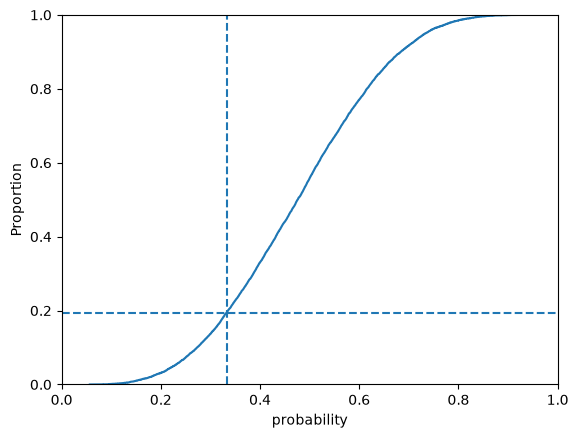

In [5]:
pos_prediction_count, threshold = th.estimate_optimal_threshold(
    prediction_probs
)

ax = sns.ecdfplot(prediction_probs)
ax.set_xlim(0, 1)
ax.hlines(1 - (pos_prediction_count / len(prediction_probs)), 0, 1, linestyles="--")
ax.vlines(threshold, 0, 1, linestyles="--")

display(pos_prediction_count)
display(threshold)

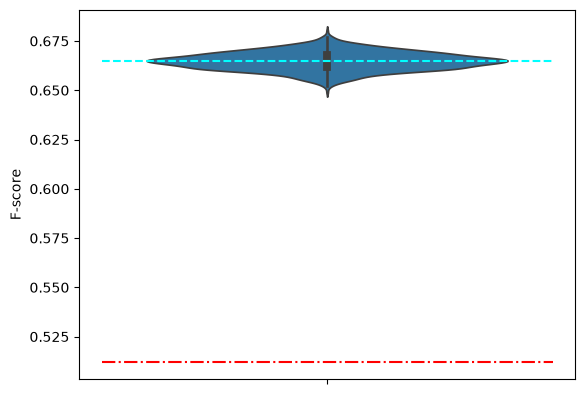

In [6]:
rng = np.random.default_rng(1)

_ = th.plot_f_scores(
    empiricals=th.sample_probable_f_scores(
        rng,
        1000,
        prediction_probs,
        pos_prediction_count
    ),
    calculated=2 * threshold,
    reported=0.51195,
)

## Make the submission

Rank test observations by their predicted probability. Assign class `1` to the `pos_prediction_count` highest-probability observations and class `0` to the rest.

In [7]:
predictions = prediction_probs.sort_values(ascending=False)

predictions.iloc[:pos_prediction_count] = 1
predictions.iloc[pos_prediction_count:] = 0

predictions = predictions.astype(np.int8).sort_index()
predictions.name = "Y"

display(predictions.head())
display(predictions.value_counts().sort_index())

ID
15001    0
15002    1
15003    1
15004    0
15005    0
Name: Y, dtype: int8

Y
0    1941
1    8059
Name: count, dtype: int64

In [8]:
import pathlib

submission_filepath = pathlib.Path("./submissions/logreg.csv")
submission_filepath.parent.mkdir(parents=True, exist_ok=True)

print(f"Saving submission file to {submission_filepath}")
predictions.to_csv(submission_filepath)

Saving submission file to submissions/logreg.csv
